# Neteja i comprovació de dades

In [32]:
# Importació de llibreries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
# Importació i primera ullada 

df = pd.read_csv("./dades/customers.csv")
df.head(15)

,customer_id,age,city,channel_preference,annual_spend,avg_order_value,orders_last_12m,returns_ratio,bike_interest,service_interest,snapshot_date,tenure_months,days_since_last_order,returned_orders_last_12m
0,C00001,48.0,Alzira,store,4566.25,913.25,5,0.0000,electric,low,2026-06-30,67,54.0,0
1,C00002,38.0,Carcaixent,store,3835.08,639.18,6,0.0000,electric,low,2026-06-30,95,23.0,0
2,C00003,43.0,Gandia,store,1159.47,128.83,9,0.0000,urban,medium,2026-06-30,9,1.0,0
3,C00004,59.0,Carcaixent,store,2702.07,300.23,9,0.1111,electric,low,2026-06-30,79,84.0,1
4,C00005,18.0,Gandia,ecommerce,304.05,101.35,3,0.0000,electric,low,2026-06-30,89,73.0,0
5,C00006,41.0,Tavernes,ecommerce,943.14,157.19,6,0.0000,service,medium,2026-06-30,44,296.0,0
6,C00007,38.0,Tavernes,store,1650.60,183.40,9,0.0000,mountain,high,2026-06-30,95,93.0,0
7,C00008,18.0,Gandia,store,231.90,115.95,2,0.5000,service,high,2026-06-30,106,113.0,1
8,C00009,27.0,Carcaixent,ecommerce,1219.52,152.44,8,0.0000,service,medium,2026-06-30,117,40.0,0
9,C00010,25.0,Sueca,ecommerce,1092.63,156.09,7,0.0000,urban,low,2026-06-30,45,39.0,0


In [34]:
# Dimensio i tipus de les dades

print("Dimensions:", df.shape)
print(df.dtypes)

Dimensions: (2000, 14)
customer_id                     str
age                         float64
city                            str
channel_preference              str
annual_spend                float64
avg_order_value             float64
orders_last_12m               int64
returns_ratio               float64
bike_interest                   str
service_interest                str
snapshot_date                   str
tenure_months                 int64
days_since_last_order       float64
returned_orders_last_12m      int64
dtype: object


In [35]:
# Comprovació de nuls

df.isnull().sum()

customer_id                  0
age                         20
city                         0
channel_preference           0
annual_spend                30
avg_order_value              0
orders_last_12m              0
returns_ratio                0
bike_interest                0
service_interest             0
snapshot_date                0
tenure_months                0
days_since_last_order       20
returned_orders_last_12m     0
dtype: int64

In [36]:
# Imputació de nuls

# Calcular la mitjana i substituïr els nuls per la mitjana
df["age"] = df["age"].fillna(df["age"].median())

# Substituïr els nuls per 0
df["annual_spend"] = df["annual_spend"].fillna(0)

# Substituïr els nuls per 0
df["days_since_last_order"] = df["days_since_last_order"].fillna(0)

In [37]:
# Comprovació de nuls després de la imputació

df.isnull().sum()

customer_id                 0
age                         0
city                        0
channel_preference          0
annual_spend                0
avg_order_value             0
orders_last_12m             0
returns_ratio               0
bike_interest               0
service_interest            0
snapshot_date               0
tenure_months               0
days_since_last_order       0
returned_orders_last_12m    0
dtype: int64

In [38]:
# Ullada a les dades per a verificar si n'hi han dades exagerades

df.describe()

,age,annual_spend,avg_order_value,orders_last_12m,returns_ratio,tenure_months,days_since_last_order,returned_orders_last_12m
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.00000,2000.0000,2000.000000
mean,43.459000,1355.86210,254.910830,5.245500,0.065912,62.36200,71.1080,0.354500
std,12.071461,1615.06013,266.428299,2.985412,0.133173,34.10932,80.2543,0.623718
min,18.000000,0.00000,19.060000,1.000000,0.000000,2.00000,0.0000,0.000000
25%,35.000000,307.18000,93.955000,3.000000,0.000000,33.00000,16.0000,0.000000
50%,43.000000,744.72000,145.560000,5.000000,0.000000,63.00000,43.5000,0.000000
75%,52.000000,1844.75250,289.390000,7.000000,0.100000,92.00000,94.0000,1.000000
max,79.000000,13968.60000,1898.820000,17.000000,1.000000,120.00000,364.0000,4.000000


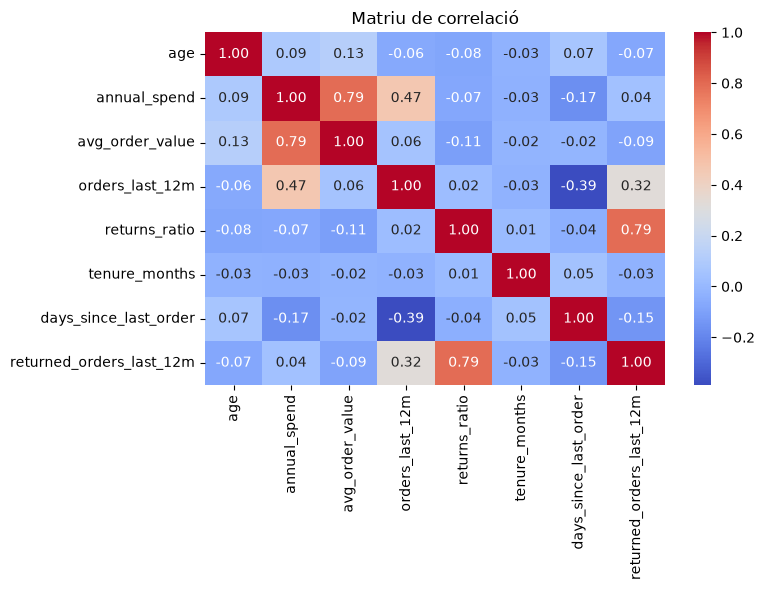

In [ ]:
# Matriu de correlació

numeric_cols = ["age", "annual_spend", "avg_order_value", "orders_last_12m", "returns_ratio", "tenure_months", "days_since_last_order", "returned_orders_last_12m"]

# Matriu de correlació
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriu de correlació")
plt.tight_layout()
plt.show()
plt.close()

In [40]:
# Separar els camps de "str" amb columnes categòriques: True, False

df_encoded = pd.get_dummies(df, columns=["city", "channel_preference", "bike_interest", "service_interest"] ,drop_first=False)

df_encoded.head()

,customer_id,age,annual_spend,avg_order_value,orders_last_12m,returns_ratio,snapshot_date,tenure_months,days_since_last_order,returned_orders_last_12m,...,city_Tavernes,channel_preference_ecommerce,channel_preference_store,bike_interest_electric,bike_interest_mountain,bike_interest_service,bike_interest_urban,service_interest_high,service_interest_low,service_interest_medium
0,C00001,48.0,4566.25,913.25,5,0.0000,2026-06-30,67,54.0,0,...,False,False,True,True,False,False,False,False,True,False
1,C00002,38.0,3835.08,639.18,6,0.0000,2026-06-30,95,23.0,0,...,False,False,True,True,False,False,False,False,True,False
2,C00003,43.0,1159.47,128.83,9,0.0000,2026-06-30,9,1.0,0,...,False,False,True,False,False,False,True,False,False,True
3,C00004,59.0,2702.07,300.23,9,0.1111,2026-06-30,79,84.0,1,...,False,False,True,True,False,False,False,False,True,False
4,C00005,18.0,304.05,101.35,3,0.0000,2026-06-30,89,73.0,0,...,False,True,False,True,False,False,False,False,True,False
